In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
crop_df = pd.read_csv(r"C:\Users\DC\Downloads\crop_yield.csv")

In [3]:
crop_df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [4]:
crop_df.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [10]:
crop_df.dtypes

FARM_ID                str
CROP_TYPE              str
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE           str
DISTRICT               str
SEASON                 str
FERTILIZER_USED        str
YIELD_VALUE          int64
dtype: object

In [11]:
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [13]:
crop_df.describe(include='object')

C:\Users\DC\AppData\Local\Temp\ipykernel_26264\3503768652.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  crop_df.describe(include='object')


,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [14]:
crop_df = crop_df.dropna(subset=['YIELD_KG'])

In [15]:
crop_df['AREA_ACRES'] = crop_df['AREA_ACRES'].fillna(crop_df['AREA_ACRES'].mean())

In [16]:
crop_df['DISTRICT'] = crop_df['DISTRICT'].fillna('Unknown')

In [17]:
crop_df['FERTILIZER_USED'] = crop_df['FERTILIZER_USED'].fillna('No')

In [18]:
crop_df['YIELD_VALUE'] = crop_df['YIELD_VALUE'].fillna( crop_df['YIELD_VALUE'].mean() )

In [19]:
crop_df['HARVEST_DATE'] = pd.to_datetime(crop_df['HARVEST_DATE'], errors='coerce', format='%d/%m/%Y' )

In [21]:
crop_df['FARM_ID'] = crop_df['FARM_ID'].str.replace('F', '').astype(int)

In [22]:
crop_df.isnull().sum()

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

In [23]:
crop_df.dtypes

FARM_ID                     int64
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object

In [26]:
total_yeild = crop_df.groupby('CROP_TYPE').agg({'YIELD_KG': 'sum'})
total_yeild

,YIELD_KG
CROP_TYPE,
Maize,1112500.0
Rice,1638000.0
Sugarcane,592000.0
Wheat,2035500.0


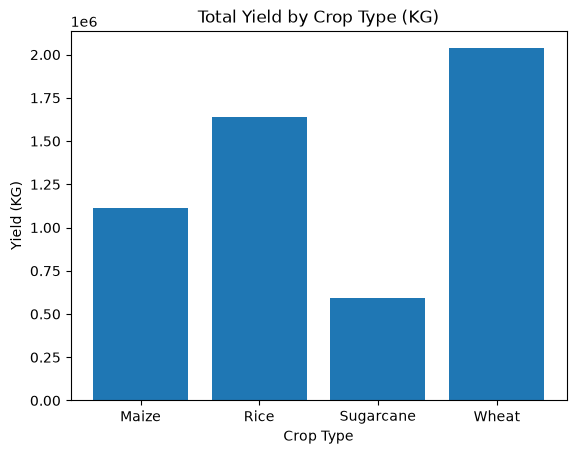

In [42]:
x = total_yeild.index
y = total_yeild['YIELD_KG']

plt.bar(x, y )
plt.xlabel('Crop Type')
plt.ylabel('Yield (KG)')
plt.title('Total Yield by Crop Type (KG)')
plt.show()

In [33]:
pivot_yield = crop_df.pivot_table(values='YIELD_KG', index='HARVEST_DATE', aggfunc='sum' )
pivot_yield

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0


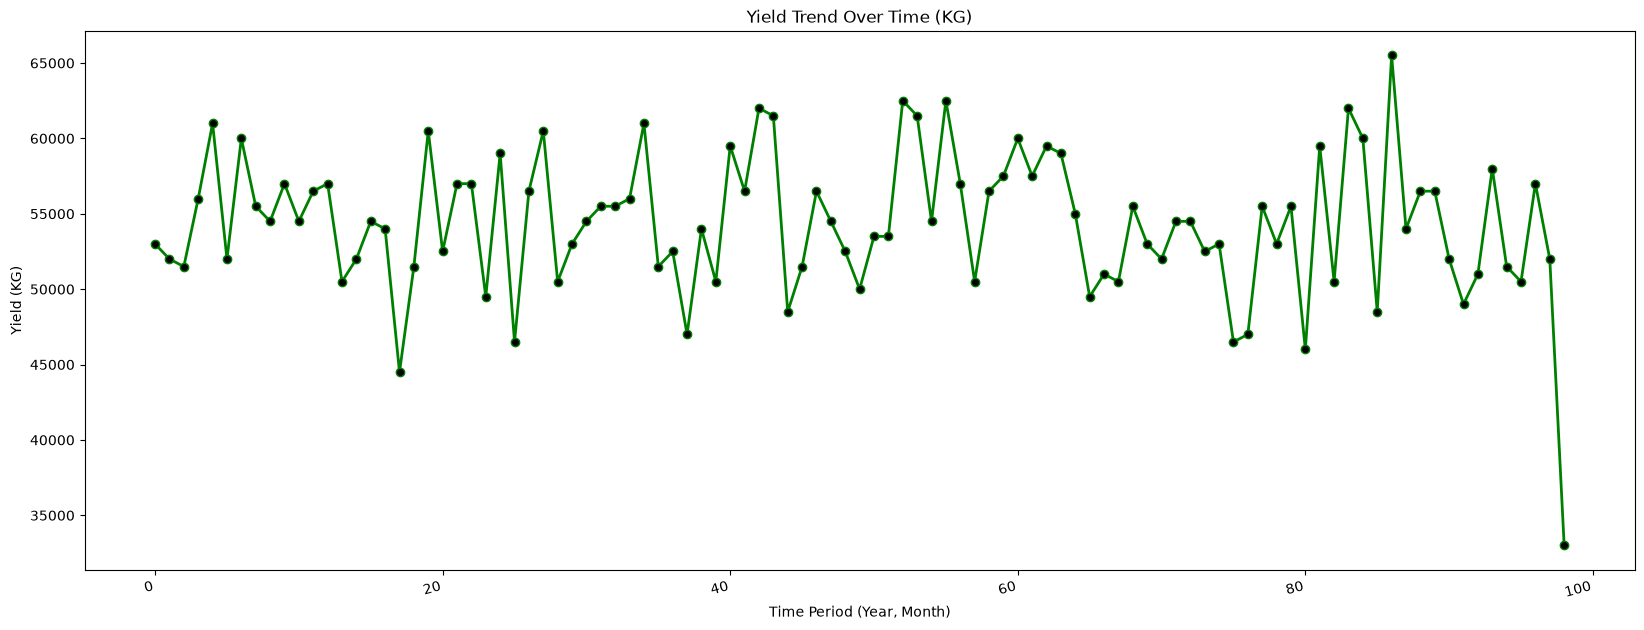

In [40]:
crop_df['year'] = crop_df['HARVEST_DATE'].dt.year
crop_df['month'] = crop_df['HARVEST_DATE'].dt.month
monthly_yield = crop_df.groupby(['year', 'month'])['YIELD_KG'].sum()

plt.figure(figsize=(20, 7))
plt.xticks(rotation=15, ha="right")
plt.plot(range(len(monthly_yield)), monthly_yield.values, color="green", ls="-", lw=2, marker="o", ms=6, markerfacecolor="black")
plt.xlabel('Time Period (Year, Month)')
plt.ylabel('Yield (KG)')
plt.title('Yield Trend Over Time (KG)')
plt.savefig('crop_yield_trend.png', dpi=300, bbox_inches='tight')
plt.show()

